# Implementing dependent calibration parameters

Import relevant libraries and create fitting engine.

In [70]:
from fitting_engine import FittingEngine
import numpy as np
import matplotlib.pyplot as plt

engine = FittingEngine(verbose=True)

Define properties of the test data.

In [71]:
# slicing properties
n_points = 30
true_y_err_std = 0.05
x_length = 3

# material properties
true_order = 0.0
true_order_std = 0.0
true_sigma_phi = 5
true_mu = 5

# actual sample parameters
true_t_exposure_1 = 1_000

# calibration sample parameters
calibration_t_exposure = [1]

Generate test data from the given parameters.

In [72]:
# generate calibration data with random perturbation from true values
calibration_x_data = []
calibration_y_data = []
calibration_y_err_std = []
for i, t_exposure in enumerate(calibration_t_exposure):
    calibration_x_data.append(np.linspace(0, x_length, n_points))
    # genearte y data using the mathematical model for single exposure
    calibration_y_data.append(engine.models.expo(calibration_x_data[i],
        true_order, true_sigma_phi, true_mu, t_exposure))
    # add random perturbation
    perturbation = np.random.normal(loc=0.0, scale=true_y_err_std,
        size=calibration_x_data[i].shape)

    calibration_y_data[i] += perturbation

    calibration_y_err_std.append(np.full(len(calibration_x_data[0]),
        true_y_err_std))

# generate measurement sample data
x_data = np.linspace(0, x_length, n_points)
y_data = engine.models.expo(x_data, true_order, true_sigma_phi, true_mu,
    true_t_exposure_1)
# add random perturbation
perturbation = np.random.normal(loc=0.0, scale=true_y_err_std,
    size=x_data.shape)
y_data += perturbation

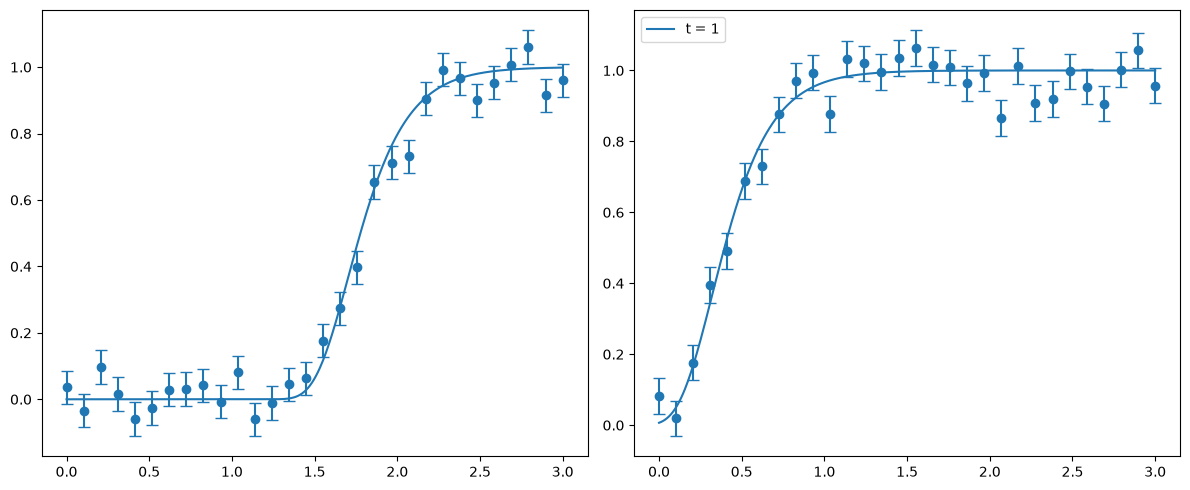

In [73]:
plt.figure(figsize=(12, 5))

# plot measurement sample and true curve
plt.subplot(1, 2, 1)

x_curve_plot = np.linspace(0, x_length, 500)
y_curve_plot = engine.models.expo(x_curve_plot, true_order,
    true_sigma_phi, true_mu, true_t_exposure_1)

plt.errorbar(x_data, y_data, yerr=true_y_err_std, fmt="o",
    capsize=4, color="C0")
plt.plot(x_curve_plot, y_curve_plot, color="C0")

# plot calibration samples and fitted curves
plt.subplot(1, 2, 2)

for i, t_exposure in enumerate(calibration_t_exposure):
    color = f"C{i % 10}"

    plt.errorbar(calibration_x_data[i], calibration_y_data[i],
        yerr=calibration_y_err_std[i], fmt="o", capsize=4,
        color=color)

    y_curve_plot = engine.models.expo(x_curve_plot, true_order,
        true_sigma_phi, true_mu, t_exposure)

    plt.plot(x_curve_plot, y_curve_plot, color=color,
        label=f"t = {t_exposure:g}")

plt.legend()
plt.tight_layout()
plt.show()

Prepare the data for the subseuent calibration fit. The multiple calibration data sets are concatenated into one large array. The `t_exposure` parameter is then given as an array for each datapoint, not as one float used for all points. This allows fitting calibration samples with different exposure at once and is the best way to handle this. 

In [74]:
# combine individual calibration samples into one large dataset
calibration_x_data_combined = np.concatenate(calibration_x_data)
calibration_y_data_combined = np.concatenate(calibration_y_data)
calibration_y_err_std_combined = np.concatenate(calibration_y_err_std)

# each datapoint gets an individual t_exposure value for the global fit
calibration_t_exposure_combined = np.concatenate(
    [np.full(n_points, t_exposure) for t_exposure in calibration_t_exposure])

# known parameters for the initial guess
known_params = {"order": true_order,
    "t_exposure_1": calibration_t_exposure_combined}

# known parameter distributions
known_params_distribution = {
    ("order",): (true_order, true_order_std),
    ("t_exposure_1",): (calibration_t_exposure_combined, 0.0)
}

# bounds for uniform priors
free_params_bounds = {
    "sigma_phi": engine.param_bounds.val.sigma_phi,
    "mu": engine.param_bounds.val.mu
}

Perform `bayesian_fit` on the data to obtain `sigma_phi` and `mu` from the calibration.

In [75]:
# get initial guess
initial_guess = engine.get_initial_guess(calibration_x_data_combined,
    calibration_y_data_combined, engine.models.expo, known_params,
    bounds=free_params_bounds, y_err_std=calibration_y_err_std_combined)

# add initial values of uncertain known parameters
if true_order_std > 0:
    initial_guess["order"] = true_order

# bayesian fit
calibration_fit_result = engine.bayesian_fit(10_000, 2_000,
    calibration_x_data_combined, calibration_y_data_combined,
    calibration_y_err_std_combined, engine.models.expo,
    initial_guess, free_params_bounds, known_params_distribution)

print(calibration_fit_result.success, calibration_fit_result.ess)

100%|██████████| 10000/10000 [00:02<00:00, 3615.57it/s]


True {'sigma_phi': 9106.22289373316, 'mu': 9268.479481971168}


Get a probabilty density function from the joint samples

In [76]:

import numpy as np
from scipy.ndimage import gaussian_filter
from scipy.interpolate import RegularGridInterpolator


def get_joint_logpdf(joint_samples, param_names, ess):
    """
    A function that estimates a joint log-probability density function.

    Uses a Gaussian-smoothed multidimensional histogram to estimate a
    continuous joint probability distribution from joint parameter samples.
    The samples are transformed into whitened coordinates to account for
    correlations between parameters. The Gaussian kernel bandwidth is
    determined according to Scott's rule using the effective sample size.
    The histogram resolution is chosen according to the kernel bandwidth.
    The probability density is interpolated for efficient evaluation
    during MCMC sampling.

    Args:
        joint_samples (list(dict(str: float))): List of dictionaries
            containing simultaneous parameter samples.
        param_names (tuple(str)): Tuple containing the names of the
            parameters for which the joint distribution is estimated.
        ess (dict(str: float)): Dict mapping the parameter names to their
            effective sample sizes.

    Returns:
        callable: Function taking the parameter values as positional
            arguments and returning the scalar joint log-probability density.
    """

    samples = np.array([
        [sample[name] for name in param_names]
        for sample in joint_samples
    ])

    ndim = len(param_names)
    effective_sample_size = min(ess[name] for name in param_names)

    # calculate whitening transformation from the sample covariance
    mean = np.mean(samples, axis=0)
    cov = np.atleast_2d(np.cov(samples, rowvar=False))
    cholesky = np.linalg.cholesky(cov)
    whitening = np.linalg.inv(cholesky)

    # transform samples into whitened coordinates
    whitened_samples = (samples - mean) @ whitening.T

    # determine Gaussian kernel bandwidth according to Scott's rule
    bandwidth = effective_sample_size**(-1 / (ndim + 4))

    # use five histogram bins per kernel standard deviation
    target_bin_width = bandwidth / 5

    # extend the histogram beyond the Gaussian kernel support
    padding = 5 * bandwidth + 2 * target_bin_width

    # determine histogram bin edges for each dimension
    edges = []

    for s in whitened_samples.T:
        lower = s.min() - padding
        upper = s.max() + padding
        n_bins = int(np.ceil((upper - lower) / target_bin_width))

        edges.append(np.linspace(lower, upper, n_bins + 1))

    # calculate multidimensional histogram
    hist, edges = np.histogramdd(whitened_samples, bins=edges)

    # calculate bin centers and widths
    axes = [(e[:-1] + e[1:]) / 2 for e in edges]
    bin_widths = np.array([e[1] - e[0] for e in edges])

    # smooth histogram using a Gaussian kernel
    density = gaussian_filter(hist, sigma=bandwidth / bin_widths,
        mode="constant", cval=0.0, truncate=5.0)

    # normalize probability density in the original parameter space
    density /= np.sum(density) * np.prod(bin_widths) \
        * np.prod(np.diag(cholesky))

    # create interpolator
    interpolator = RegularGridInterpolator(axes, density,
        method="linear", bounds_error=False, fill_value=0.0)

    def logpdf(*params):
        whitened_params = whitening @ (np.asarray(params) - mean)
        probability_density = float(interpolator([whitened_params])[0])

        if probability_density <= 0:
            return -np.inf

        return np.log(probability_density)

    return logpdf

Create the calibration log probability density function from the joint samples.

In [77]:
calibration_logpdf = get_joint_logpdf(calibration_fit_result.joint_samples,
    ("sigma_phi", "mu"), calibration_fit_result.ess)

Visualize the function.

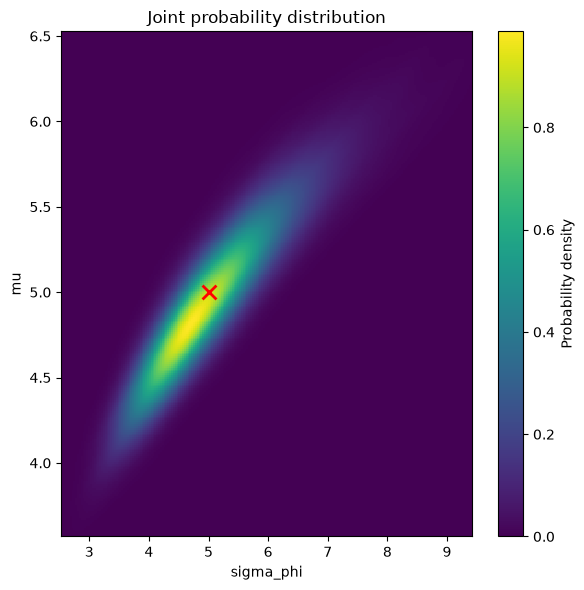

In [78]:
sigma_phi_joint = np.array(
    [sample["sigma_phi"] for sample in calibration_fit_result.joint_samples])
mu_joint = np.array(
    [sample["mu"] for sample in calibration_fit_result.joint_samples])

# determine initial plot limits from joint samples
x_min, x_max = sigma_phi_joint.min(), sigma_phi_joint.max()
y_min, y_max = mu_joint.min(), mu_joint.max()

# add padding to include distribution tails
x_padding = 0.2 * (x_max - x_min)
y_padding = 0.2 * (y_max - y_min)

# create evaluation grid
x = np.linspace(x_min - x_padding, x_max + x_padding, 500)
y = np.linspace(y_min - y_padding, y_max + y_padding, 500)
X, Y = np.meshgrid(x, y)

# evaluate probability density
density = np.exp(np.array([
    calibration_logpdf(sigma_phi, mu)
    for sigma_phi, mu in zip(X.ravel(), Y.ravel())
])).reshape(X.shape)

# determine region of significant probability density
mask = density >= 0.01 * density.max()

x_min, x_max = X[mask].min(), X[mask].max()
y_min, y_max = Y[mask].min(), Y[mask].max()

# add 5% padding for visualization
x_padding = 0.05 * (x_max - x_min)
y_padding = 0.05 * (y_max - y_min)

# plot joint probability distribution
plt.figure(figsize=(6, 6))
plt.pcolormesh(X, Y, density, shading="auto", cmap="viridis")
plt.colorbar(label="Probability density")
plt.xlabel("sigma_phi")
plt.ylabel("mu")
plt.title("Joint probability distribution")
plt.xlim(x_min - x_padding, x_max + x_padding)
plt.ylim(y_min - y_padding, y_max + y_padding)
plt.scatter(true_sigma_phi, true_mu, color="red", marker="x",
    s=100, linewidths=2, zorder=10)
plt.tight_layout()
plt.show()

Now let's continue with the real fit. We will use the full joint posterior distribution of `sigma_phi` and `mu`.

In [79]:
# known parameters for the initial guess
known_params = {
    "order": true_order,
    "sigma_phi": calibration_fit_result.best_fit["sigma_phi"],
    "mu": calibration_fit_result.best_fit["mu"]
}

# known parameter distributions
known_params_distribution = {
    ("order",): (true_order, true_order_std),
    ("sigma_phi", "mu"): calibration_logpdf
}

# bounds for uniform priors
free_params_bounds = {
    "t_exposure_1": (0, 1_000_000)
}

# get initial guess for free parameters
initial_guess = engine.get_initial_guess(x_data, y_data,
    engine.models.expo, known_params, bounds=free_params_bounds,
    y_err_std=true_y_err_std)

# add initial values of uncertain known parameters
initial_guess["sigma_phi"] = known_params["sigma_phi"]
initial_guess["mu"] = known_params["mu"]

if true_order_std > 0:
    initial_guess["order"] = true_order

dating_fit_result = engine.bayesian_fit(10_000, 2_000,
    x_data, y_data, true_y_err_std, engine.models.expo,
    initial_guess, free_params_bounds, known_params_distribution)

print(dating_fit_result.success)
print(dating_fit_result.best_fit)
print(dating_fit_result.confidence_interval)

dating_samples = dating_fit_result.marginal_samples["t_exposure_1"]

100%|██████████| 10000/10000 [00:07<00:00, 1359.45it/s]


True
{'t_exposure_1': 694.6493305531361}
{'t_exposure_1': (460.2941617876886, 1093.0078553905541)}


Plot the resulting distribution.

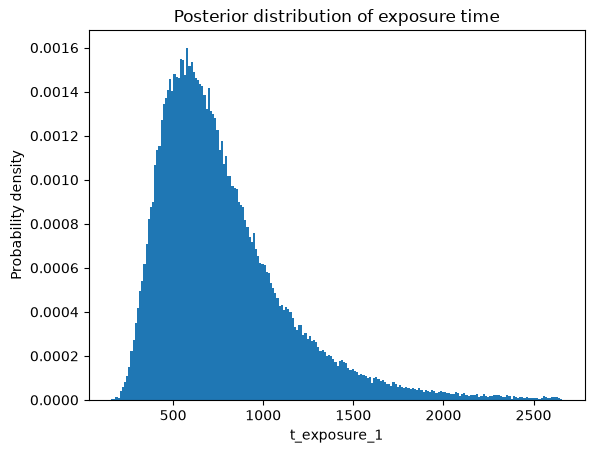

In [80]:
# plot posterior distribution of exposure time
plt.hist(dating_samples, bins="fd", density=True,
    range=tuple(np.quantile(dating_samples, [0.0, 0.995])))
plt.xlabel("t_exposure_1")
plt.ylabel("Probability density")
plt.title("Posterior distribution of exposure time")
plt.show()